# Task 1: Represent a message $m$ as an $n$-qubit basis state $|m\rangle$

$n = 6$ qubits, $d = 2^n = 64$, $M = d = 64$ messages $m \in \{0,\dots,63\}$. The register starts in $|000000\rangle$; an X gate on every qubit whose bit of $m$ is 1 prepares $|m\rangle$.


In [7]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector

N = 6
d = 64
M = 64
messages = list(range(64))

In [8]:
def ket(m, d):
    return Statevector.from_int(m, d)


def encode_message(m, n):
    """Return an n-qubit circuit preparing |m> from |0...0>."""
    if not (0 <= m < 2**n):
        raise ValueError(f"m={m} does not fit in n={n} qubits")

    qr = QuantumRegister(n, "msg")
    qc = QuantumCircuit(qr)

    for q in range(n):
        if (m >> q) & 1:
            qc.x(qr[q])

    return qc

In [9]:
m = 37
qc = encode_message(m, N)
print(qc.draw("text"))

sv = Statevector.from_instruction(qc)
probs = sv.probabilities_dict()
print("probabilities:", probs)
print("decoded m =", int(max(probs, key=probs.get), 2))

       ┌───┐
msg_0: ┤ X ├
       └───┘
msg_1: ─────
       ┌───┐
msg_2: ┤ X ├
       └───┘
msg_3: ─────
            
msg_4: ─────
       ┌───┐
msg_5: ┤ X ├
       └───┘
probabilities: {np.str_('100101'): np.float64(1.0)}
decoded m = 37


In [10]:
for m in messages:
    sv_m = Statevector.from_instruction(encode_message(m, N))
    assert np.allclose(sv_m.data, ket(m, d).data), f"failed for m={m}"

print("✅ all", M, "messages encoded as |m>")

✅ all 64 messages encoded as |m>


In [13]:
import matplotlib.pyplot as plt
def plot_circles(state, title="", cols=8, size=1.1):
    """Draw a state in the course's circle notation.

    For every basis state |j>:
      * grey outline  = the maximum possible magnitude (1)
      * filled disk   = radius proportional to |amplitude|  (so area ~ probability)
      * dark line     = the phase of the amplitude. Our drawing convention:
                        phase 0 points straight UP and the line rotates
                        COUNTER-CLOCKWISE as the phase grows (90 deg points left).
    """
    amps = np.asarray(state.data if hasattr(state, "data") else state, dtype=complex)
    d = len(amps)
    n = int(np.log2(d))
    cols = min(cols, d)
    rows = int(np.ceil(d / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 1.15))
    axes = np.atleast_1d(axes).ravel()
    for j, ax in enumerate(axes):
        ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15)
        ax.set_aspect("equal"); ax.axis("off")
        if j >= d:
            continue
        r = abs(amps[j])
        ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.6", lw=1))
        if r > 1e-9:
            ax.add_patch(plt.Circle((0, 0), r, color="#4a90d9", alpha=0.75))
            phi = np.angle(amps[j])
            ax.plot([0, -r * np.sin(phi)], [0, r * np.cos(phi)], color="#0b2545", lw=1.6)
        ax.set_title(f"|{j}>\n{j:0{n}b}", fontsize=7)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()

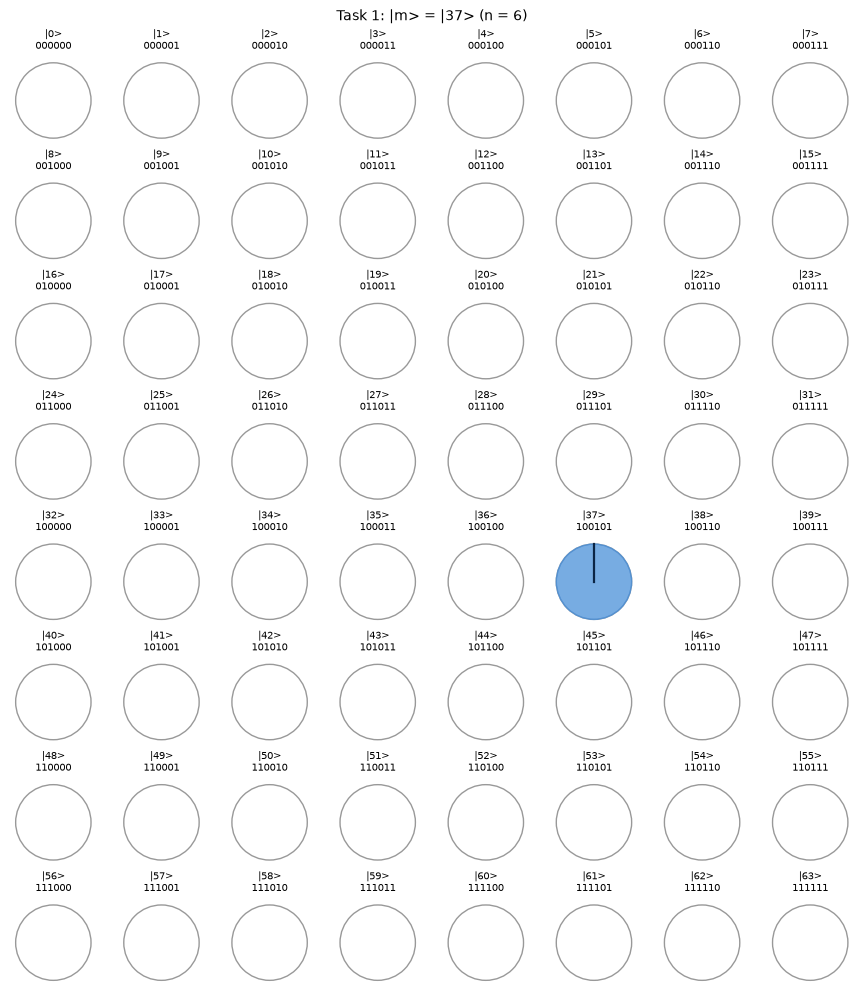

In [14]:
plot_circles(Statevector.from_instruction(encode_message(37, N)), "Task 1: |m> = |37> (n = 6)")